# Стратегия 2: Автоматическое исполнение через mkdocs-jupyter

Этот код выполняется **автоматически** при сборке сайта `mkdocs build`.

**Плюсы:**
- Код и результат в одном месте
- Воспроизводимость
- Не нужно вручную сохранять PNG

**Минусы:**
- Медленная сборка (каждый раз пересчёт)
- Сложно кэшировать
- Проблемы с большими датасетами

In [1]:
# Все импорты в начале
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from pathlib import Path

# Настройка стилей
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 12

# Относительные пути (важно для воспроизводимости!)
ROOT = Path.cwd().parent  # Возвращаемся из notebooks/ в корень проекта
DATA_PATH = ROOT / 'data' / 'raw' / 'traffic_features.csv'

print(f"✓ Корень проекта: {ROOT}")
print(f"✓ Путь к данным: {DATA_PATH}")

✓ Корень проекта: c:\Users\Admin\Desktop\python-lab
✓ Путь к данным: c:\Users\Admin\Desktop\python-lab\data\raw\traffic_features.csv


In [2]:
# Загрузка данных
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Датасет не найден: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
print(f"✓ Загружено {len(df)} записей")
print(f"✓ Классы: {df['protocol'].unique().tolist()}")
df.head()

✓ Загружено 5000 записей
✓ Классы: ['HTTP', 'HTTPS', 'SSH', 'DNS', 'TLS1.3']


,protocol,pkt_len_mean,pkt_len_std,direction_ratio,inter_arrival_mean,entropy,tls_handshake,n_packets
0,HTTP,542.471708,148.000795,0.575045,0.014703,5.524482,0,531
1,HTTP,524.784040,184.187870,0.498320,0.005735,6.939699,0,975
2,HTTP,589.779194,203.301535,0.612724,0.012338,6.070354,0,101
3,HTTP,416.111740,243.922515,0.495007,0.009076,6.159535,0,559
4,HTTP,634.254134,192.273526,0.457167,0.008239,6.766155,0,502


C:\Users\Admin\AppData\Local\Temp\ipykernel_19716\3937244444.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax, palette='viridis')


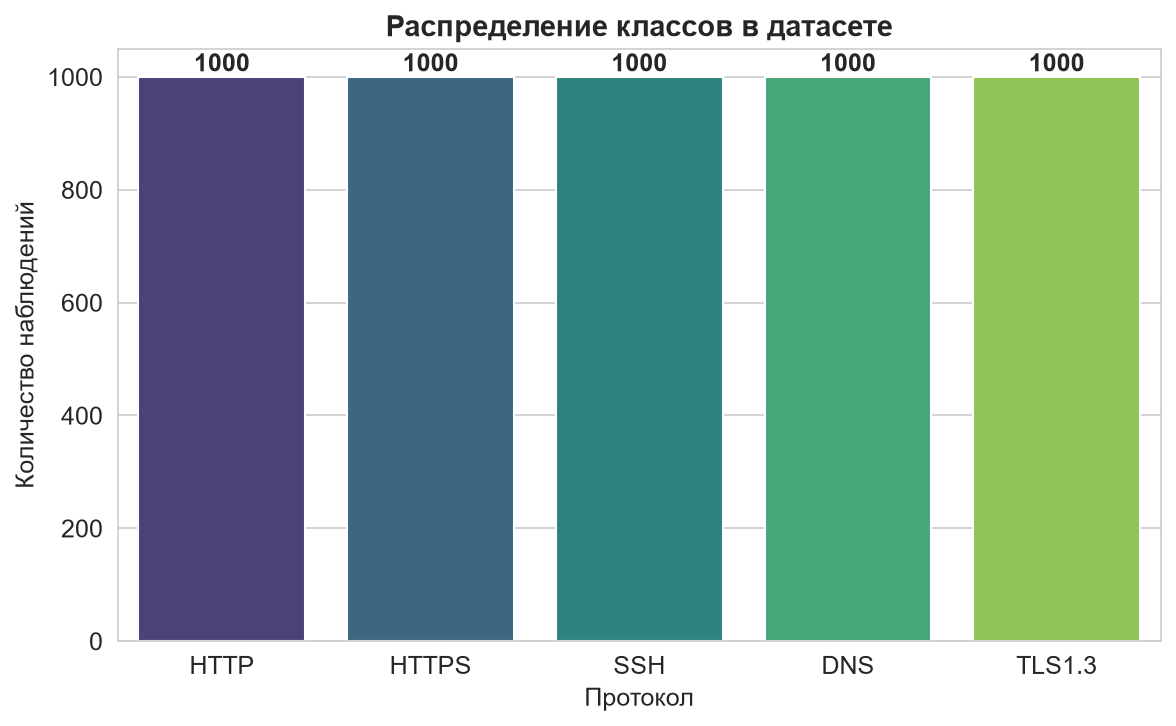

In [3]:
# Распределение классов
fig, ax = plt.subplots(figsize=(8, 5))
class_counts = df['protocol'].value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax, palette='viridis')
ax.set_title('Распределение классов в датасете', fontsize=14, fontweight='bold')
ax.set_xlabel('Протокол')
ax.set_ylabel('Количество наблюдений')
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 10, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [4]:
# Подготовка данных
feature_cols = ['pkt_len_mean', 'pkt_len_std', 'direction_ratio', 
                'inter_arrival_mean', 'entropy', 'n_packets']

X = df[feature_cols]
y = df['protocol']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Обучение модели
clf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# Метрики
report = classification_report(y_test, y_pred, output_dict=True)
accuracy = report['accuracy']

print(f"{'='*60}")
print(f"ТОЧНОСТЬ МОДЕЛИ: {accuracy:.4f}")
print(f"{'='*60}")

ТОЧНОСТЬ МОДЕЛИ: 0.9410


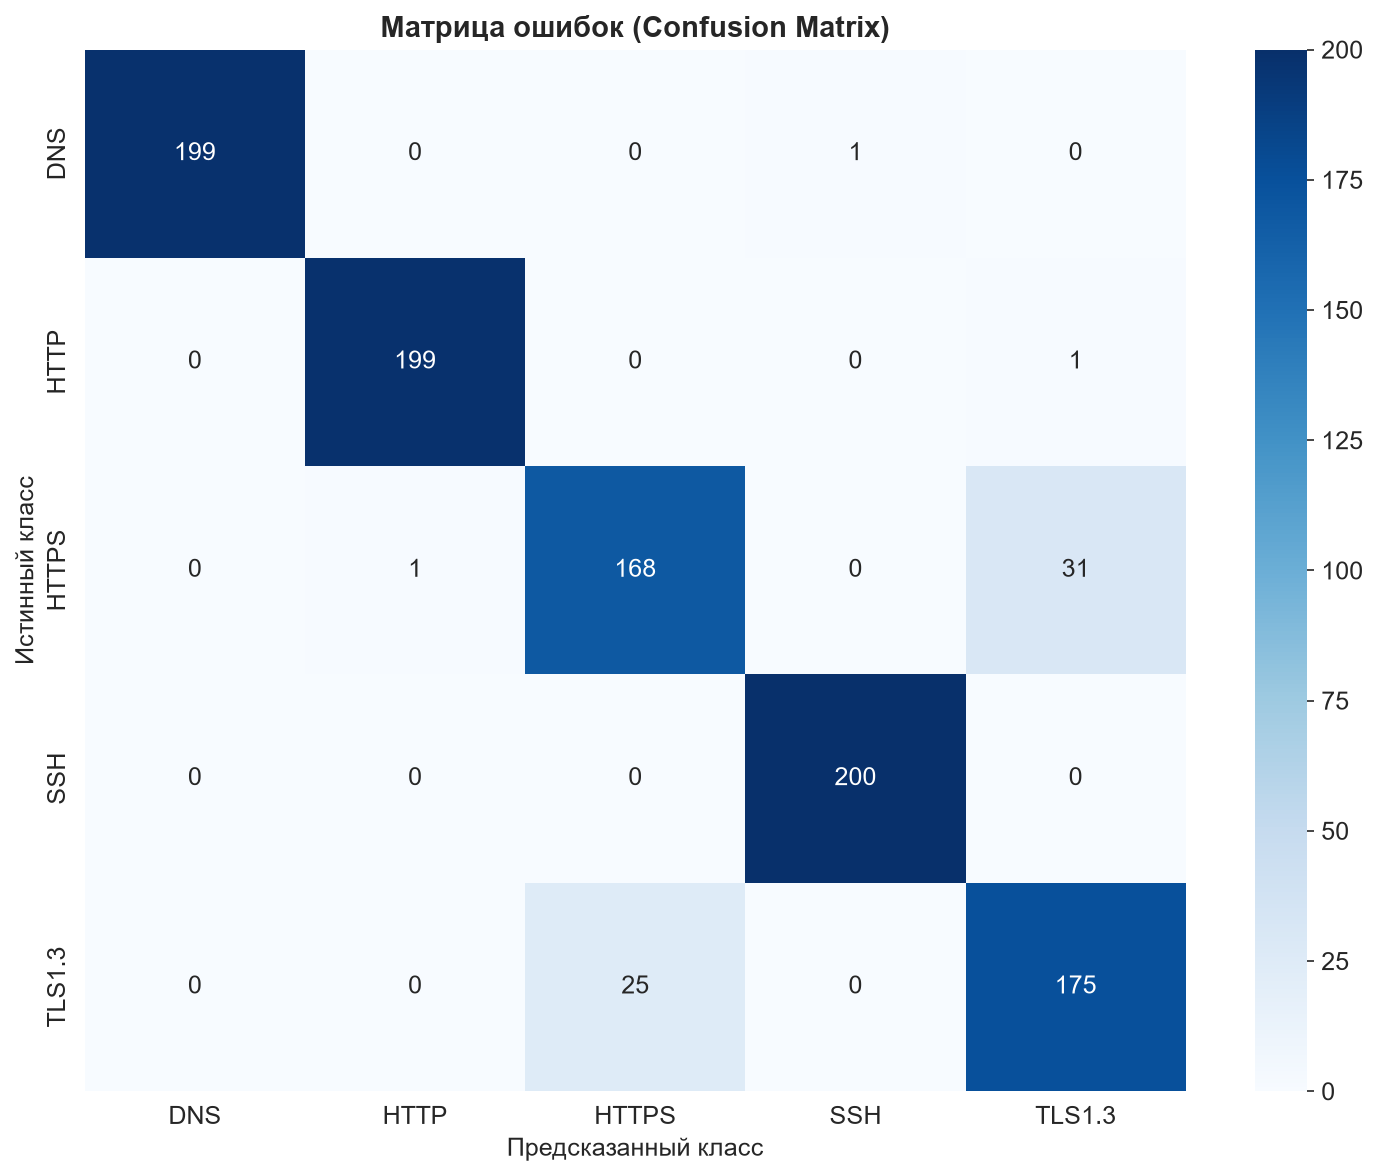

In [5]:
# Матрица ошибок
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clf.classes_, yticklabels=clf.classes_, ax=ax)
ax.set_xlabel('Предсказанный класс', fontsize=12)
ax.set_ylabel('Истинный класс', fontsize=12)
ax.set_title('Матрица ошибок (Confusion Matrix)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_19716\2019714486.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feature_cols, ax=ax, palette='viridis')


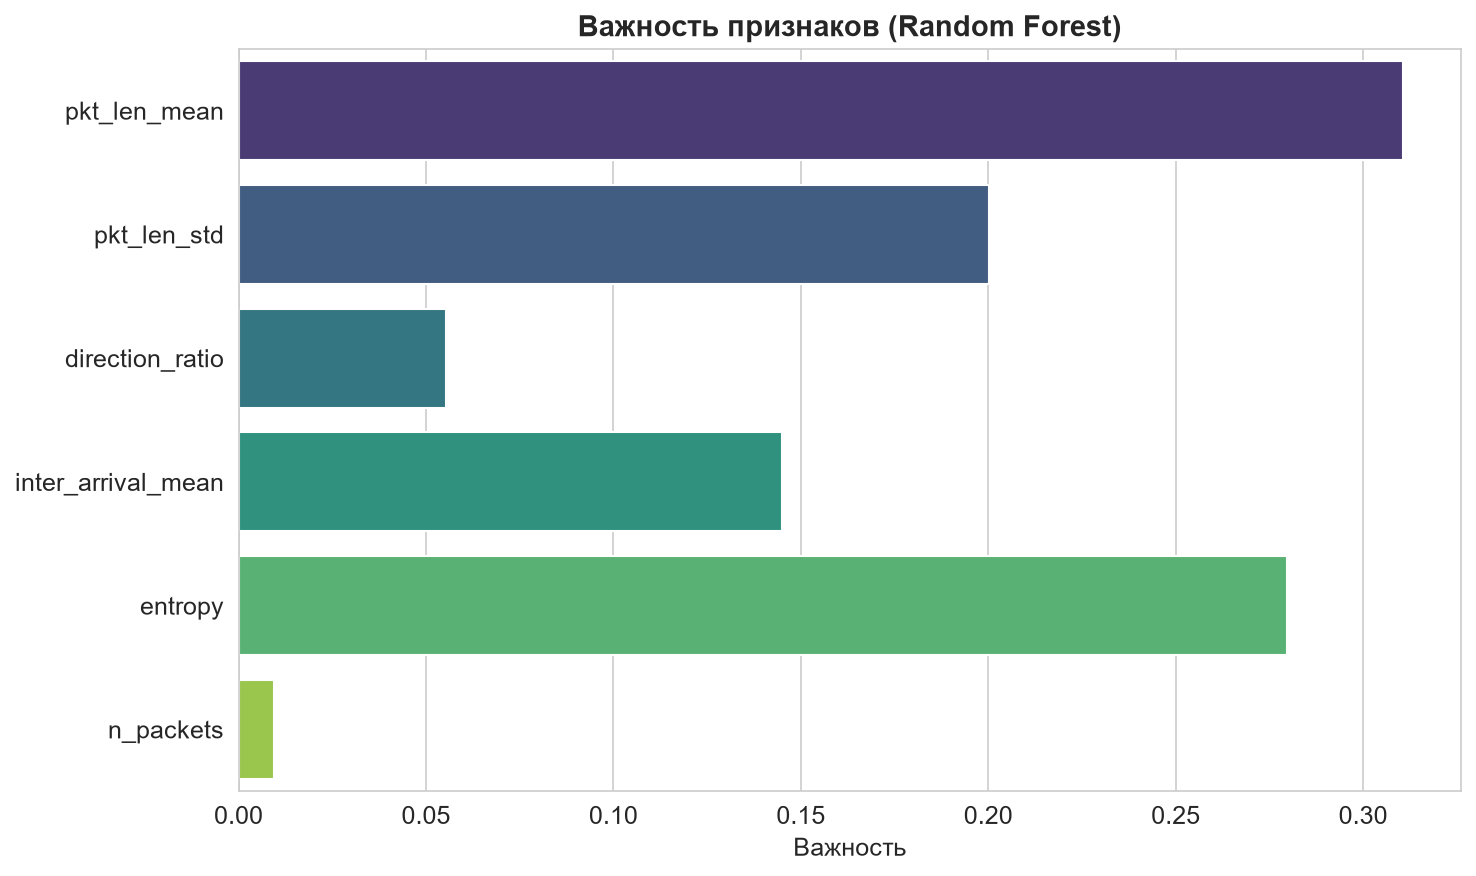

In [6]:
# Важность признаков
importances = clf.feature_importances_
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=importances, y=feature_cols, ax=ax, palette='viridis')
ax.set_title('Важность признаков (Random Forest)', fontsize=14, fontweight='bold')
ax.set_xlabel('Важность', fontsize=12)
plt.tight_layout()
plt.show()

In [7]:
## Сводная таблица метрик

| Протокол | Precision | Recall | F1-Score | Support |
|----------|-----------|--------|----------|---------|

SyntaxError: invalid syntax (1262982223.py, line 3)

In [ ]:
# Генерация Markdown-таблицы
md_table = "| Протокол | Precision | Recall | F1-Score | Support |\n"
md_table += "|----------|-----------|--------|----------|---------|\n"

for proto in sorted(report.keys()):
    if proto in ('accuracy', 'macro avg', 'weighted avg'):
        continue
    r = report[proto]
    md_table += f"| {proto} | {r['precision']:.3f} | {r['recall']:.3f} | {r['f1-score']:.3f} | {int(r['support'])} |\n"

md_table += f"| **Weighted avg** | {report['weighted avg']['precision']:.3f} | {report['weighted avg']['recall']:.3f} | {report['weighted avg']['f1-score']:.3f} | {int(report['weighted avg']['support'])} |\n"

print(md_table)